# Bearing ambiguity gate — технический отказ

## Краткий итог

Одна попытка worker остановилась **до синтеза**. Создано **0/16** аудиопотоков,
выполнено **0/8** replay. Пользователь отказался от повторного запуска.
Признаки реализованы, но их надёжность и эффект на tracking **не оценены**.
Это технический отказ, а не отрицательный научный результат.

Notebook читает только сохранённые артефакты; не синтезирует аудио и не запускает трекер.

## Контекст и методы

Два наблюдаемых признака на метод: спектральная participation и margin
от удалённого конкурента. Формулы/разделение/undefined cases и правило выбора
порогов зафиксированы до первой попытки в `BEARING_AMBIGUITY_PROTOCOL.md`
(коммит `07ad77b`). Gate выключен по умолчанию. GCC/SRP, bias/R, Qc и
оптимизационные бюджеты сохранены.

### Допущения

Синтетический transfer на двух существующих Gazebo записях. Источник/шум
непрерывны, 1/r и фиксированный фон. Общие source banks и повторные дальности
зависимы. Нет независимых реальных сеансов и iid-frame статистики.

## Данные и SHA-проверка
Проверяем исходный protocol/code snapshot, записи движения и ledger. Не заменяем отсутствующие error/coverage метрики нулями.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
if not (root / 'BEARING_AMBIGUITY_PROTOCOL.md').exists(): raise RuntimeError('Run from uav_acoustic_model or notebooks')
sys.path.insert(0, str(root))
from analysis.bearing_ambiguity_failure import audit_stop
import pandas as pd
out = root / 'results/bearing_ambiguity_gate'
audit = audit_stop(out)
manifest = json.loads((out / 'study_manifest.json').read_text())
ledger = json.loads((out / 'execution_ledger.json').read_text())
pd.DataFrame([audit])[['status','worker_attempts','actual_audio_streams','actual_replays','thresholds_selected','evaluation_accessed']]

,status,worker_attempts,actual_audio_streams,actual_replays,thresholds_selected,evaluation_accessed
0,technical_stop_user_declined_restart,1,0,0,False,False


### План, а не выполненные измерения
Матрица заморожена до расчётов; все 16 случаев остались без исследовательских результатов.

In [2]:
specs = pd.DataFrame(manifest['specs'])
specs.groupby(['split','trajectory','source_class','distance_m'], sort=False).size().rename('planned_realizations').to_frame()

planned_realizations
split       trajectory source_class           distance_m                      
development spatial    broadband              200                            2
                                              700                            2
                       nonstationary_harmonic 200                            2
                                              700                            2
evaluation  radial     broadband              200                            2
                                              700                            2
                       nonstationary_harmonic 200                            2
                                              700                            2

## Результаты
Ни development-порогов, ни bearing метрик, ни подтверждённых треков нет. Ниже показан только фактический статус выполнения, без экстраполяции качества.

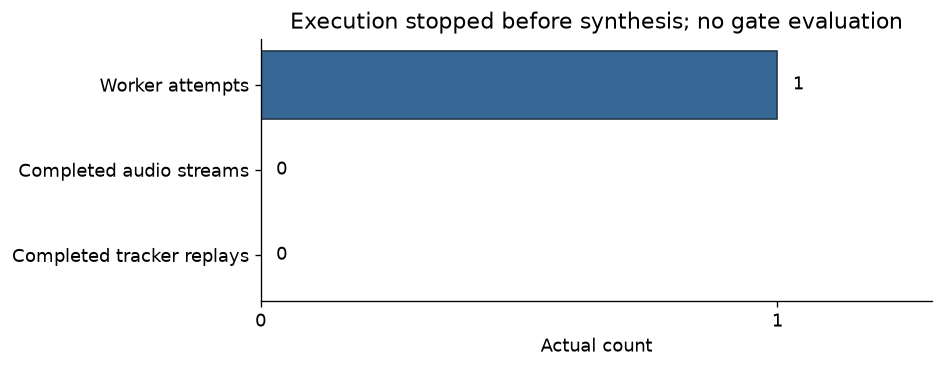

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
labels = ['Worker attempts', 'Completed audio streams', 'Completed tracker replays']
values = [audit['worker_attempts'], audit['actual_audio_streams'], audit['actual_replays']]
fig, ax = plt.subplots(figsize=(8,3.2))
bars = ax.barh(labels, values, color='#376795', edgecolor='#243746')
ax.set_xlim(0,1.3); ax.set_xticks([0,1]); ax.set_xlabel('Actual count')
ax.set_title('Execution stopped before synthesis; no gate evaluation')
for bar,value in zip(bars, values): ax.text(value+.03, bar.get_y()+bar.get_height()/2, str(value), va='center')
ax.invert_yaxis(); fig.tight_layout()
fig.savefig(out / 'execution_status.png', bbox_inches='tight')
plt.show()

In [4]:
pd.DataFrame(ledger['attempts'])[['kind','index','status','returncode','timed_out','wall_s']]

,kind,index,status,returncode,timed_out,wall_s
0,audio,0,partial,1,False,1.287011


## Выводы и следующий шаг

`KeyError: spatial`: фактический ключ записи — `spatial_manoeuvre`.
Исправление ключей обеих записей покрыто регрессионным тестом, но новая
матрица не запускалась. Исходный manifest/code/ledger сохранены; stop нельзя
обойти обычным повтором.

Ответ на исследовательский вопрос остаётся **неизвестным**. Gate не включать
по умолчанию. Для нового исследования нужны отдельное разрешение и новый
каталог; сохранить прежние лимиты. Команды — `BEARING_AMBIGUITY_RUNBOOK.md`.

Подробный отчёт — `BEARING_AMBIGUITY_REPORT.md`; stage S8 остаётся In progress.